In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [3]:
# Check column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   ho

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [4]:
# 1. Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check unknown values
print("\nUnknown values in each column:")
for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()
    if count > 0:
        print(f"{col}: {count}")

# 3. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 4. Check target distribution
print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget distribution in percentage:")
print((df["y"].value_counts(normalize=True) * 100).round(2))


Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Unknown values in each column:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Number of duplicate rows: 0

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target distribution in percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


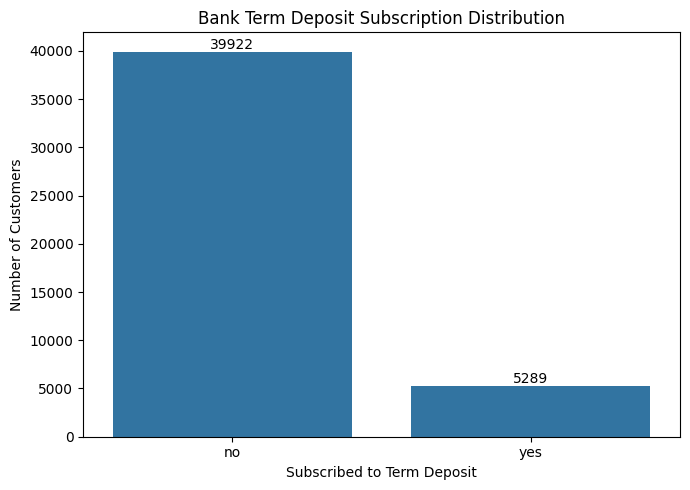

In [5]:
# Count customers who subscribed and did not subscribe
target_counts = df["y"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 5))
sns.barplot(x=target_counts.index, y=target_counts.values)

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")

for i, value in enumerate(target_counts.values):
    plt.text(i, value + 300, str(value), ha="center")

plt.tight_layout()
plt.show()

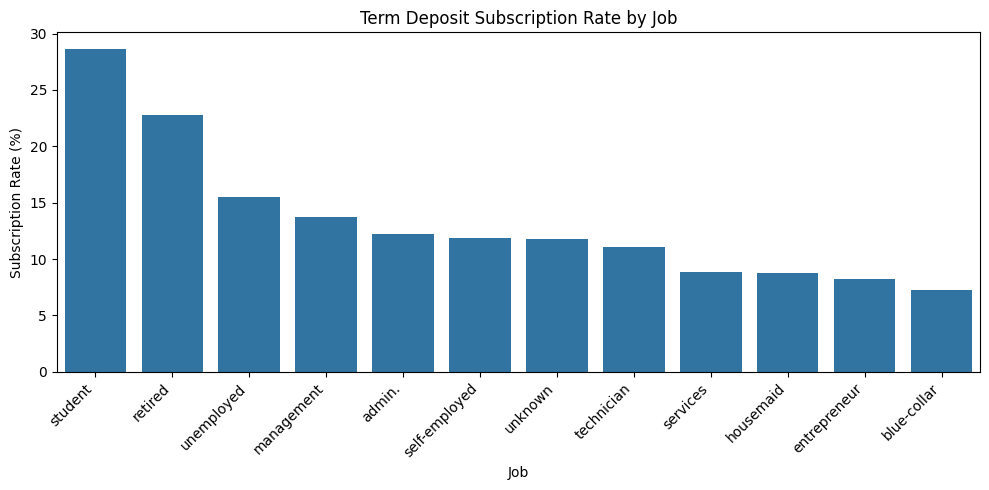

,Subscription Rate (%)
job,
student,28.68
retired,22.79
unemployed,15.50
management,13.76
admin.,12.20
self-employed,11.84
unknown,11.81
technician,11.06
services,8.88


In [6]:
# Subscription rate by job
job_rate = df.groupby("job")["y"].apply(
    lambda x: (x == "yes").mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=job_rate.index, y=job_rate.values)
plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(job_rate.round(2).to_frame("Subscription Rate (%)"))


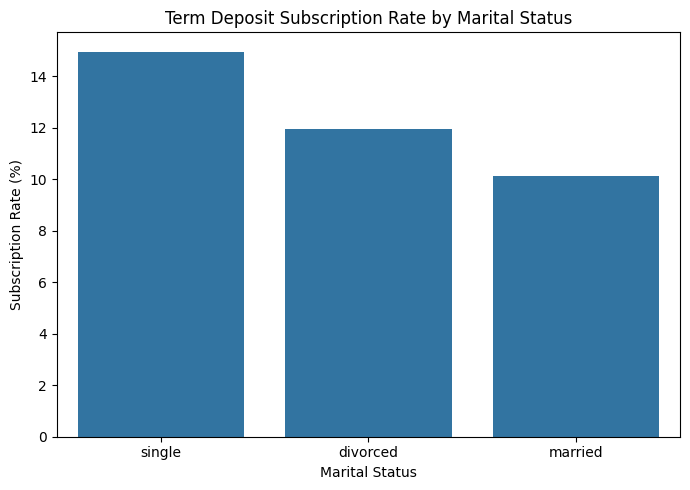

,Subscription Rate (%)
marital,
single,14.95
divorced,11.95
married,10.12


In [7]:
# Subscription rate by marital status
marital_rate = (
    df.groupby("marital")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(x=marital_rate.index, y=marital_rate.values)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

display(marital_rate.round(2).to_frame("Subscription Rate (%)"))

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Remove duration because it is not available before the call
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)
print("\nTarget classes:")
print(y.value_counts())

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training and testing split completed.")

Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target classes:
y
0    39922
1     5289
Name: count, dtype: int64

Training samples: 36168
Testing samples: 9043
Training and testing split completed.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42,
        class_weight="balanced", n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    # Each model uses the same preprocessing and training/test split
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline
    print(f"{name} trained successfully.")

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
display(results_df.round(4))

Logistic Regression trained successfully.
Decision Tree trained successfully.
KNN trained successfully.
Random Forest trained successfully.

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.8933,0.6332,0.2089,0.3141,0.7911
1,Decision Tree,0.8402,0.3059,0.2883,0.2968,0.6008
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717


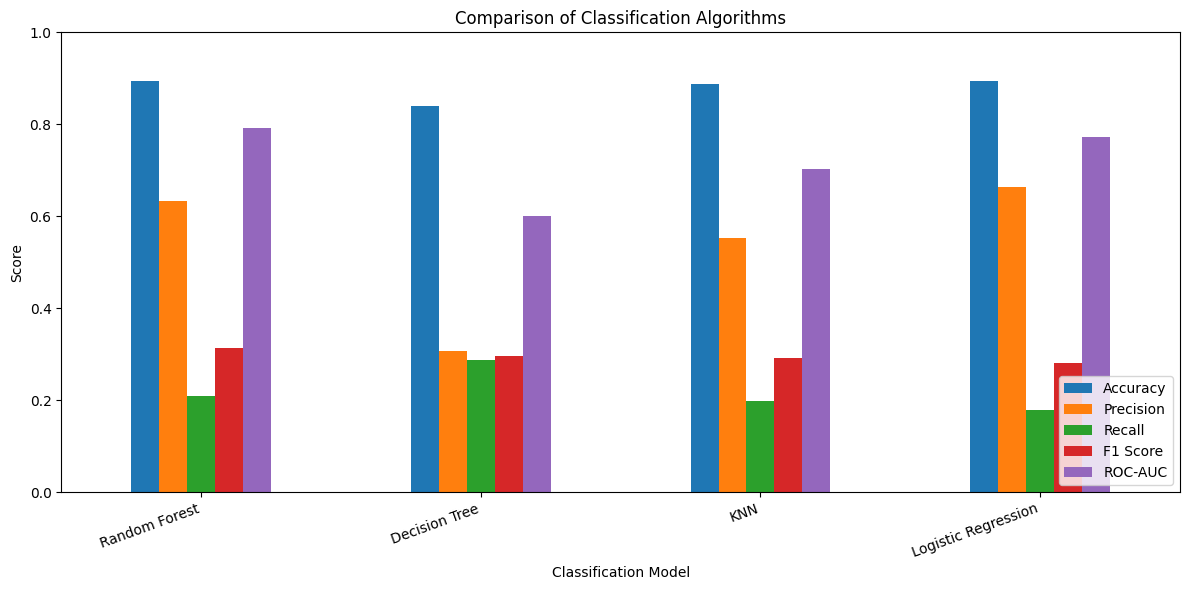

In [10]:
# Compare performance metrics across all four models
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Comparison of Classification Algorithms")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

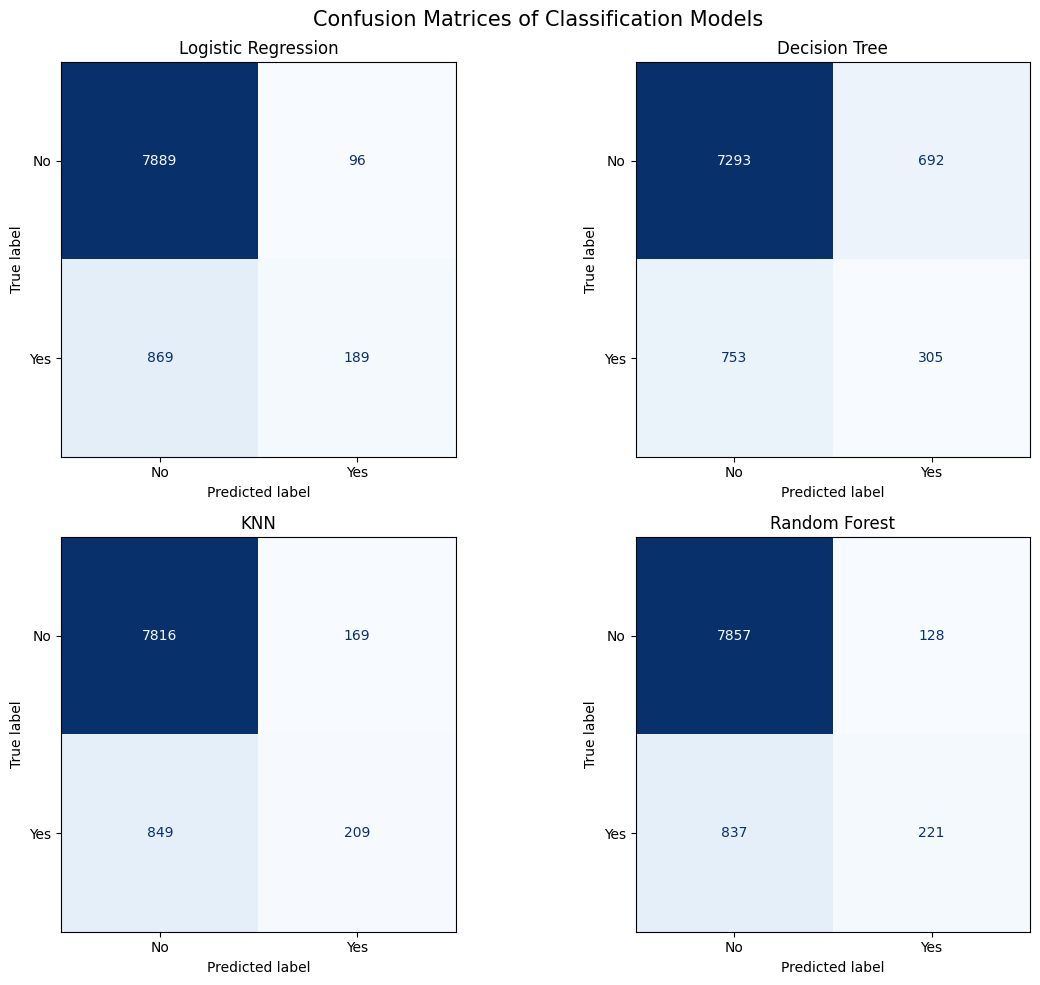

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices of Classification Models", fontsize=15)
plt.tight_layout()
plt.show()

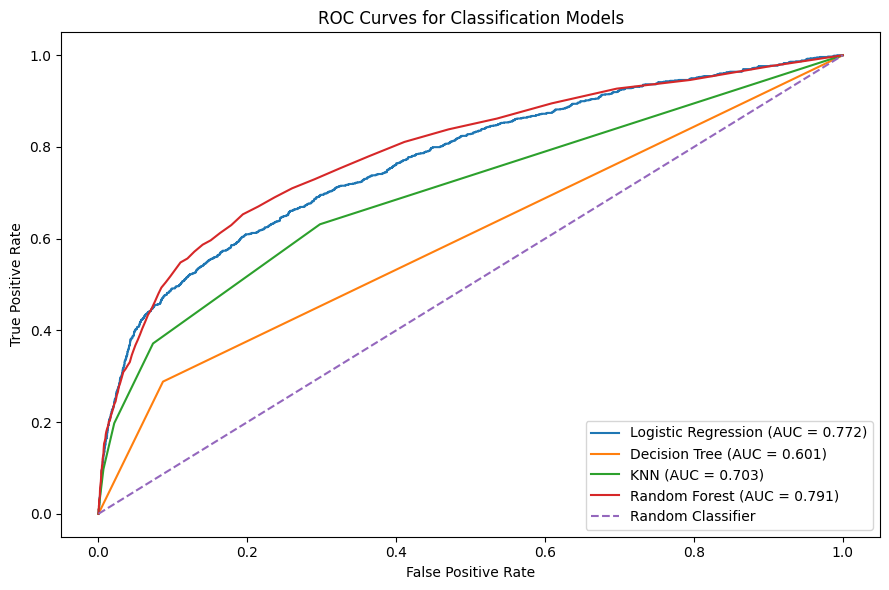

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curves for Classification Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:
# Display final model comparison
print("FINAL MODEL COMPARISON")
display(results_df.round(4))

# Identify the model with the highest F1 score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

print("\nBest model based on F1 Score:", best_model_name)

# Print the best model's metrics
best_result = results_df[
    results_df["Model"] == best_model_name
]

display(best_result.round(4))


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.8933,0.6332,0.2089,0.3141,0.7911
1,Decision Tree,0.8402,0.3059,0.2883,0.2968,0.6008
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Logistic Regression,0.8933,0.6632,0.1786,0.2815,0.7717



Best model based on F1 Score: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.8933,0.6332,0.2089,0.3141,0.7911


In [14]:
# Business insights from the dataset

print("BUSINESS INSIGHTS")
print("-" * 50)

# Overall subscription rate
subscription_rate = (df["y"] == "yes").mean() * 100
print(f"Overall subscription rate: {subscription_rate:.2f}%")

# Subscription rate by job
job_rate = df.groupby("job")["y"].apply(
    lambda x: (x == "yes").mean() * 100
).sort_values(ascending=False)

print("\nSubscription rate by job:")
display(job_rate.round(2).to_frame("Subscription Rate (%)"))

# Subscription rate by marital status
marital_rate = df.groupby("marital")["y"].apply(
    lambda x: (x == "yes").mean() * 100
).sort_values(ascending=False)

print("\nSubscription rate by marital status:")
display(marital_rate.round(2).to_frame("Subscription Rate (%)"))

# Subscription rate by contact method
contact_rate = df.groupby("contact")["y"].apply(
    lambda x: (x == "yes").mean() * 100
).sort_values(ascending=False)

print("\nSubscription rate by contact method:")
display(contact_rate.round(2).to_frame("Subscription Rate (%)"))

BUSINESS INSIGHTS
--------------------------------------------------
Overall subscription rate: 11.70%

Subscription rate by job:


,Subscription Rate (%)
job,
student,28.68
retired,22.79
unemployed,15.50
management,13.76
admin.,12.20
self-employed,11.84
unknown,11.81
technician,11.06
services,8.88



Subscription rate by marital status:


,Subscription Rate (%)
marital,
single,14.95
divorced,11.95
married,10.12



Subscription rate by contact method:


,Subscription Rate (%)
contact,
cellular,14.92
telephone,13.42
unknown,4.07
